# Clustering de documents

## Imports

In [6]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

In [7]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /home/minasema/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [8]:
data_path = "../../data/txt/"

## Choisir une décennie

In [9]:
ANNEES = [1960,1961,1962,1963,1964,1965,1966,1967,1968,1969]

## Charger tous les  fichiers de la décennie et en créer une liste de textes

In [10]:
files = []
for f in sorted(os.listdir(data_path)):
    for annee in ANNEES:
        if f"_{annee}-" in f:
            files.append(f)
            break

In [11]:
# Exemple de fichiers
files[5:]

['KB_JB838_1960-01-27_01-00006.txt',
 'KB_JB838_1960-01-28_01-00011.txt',
 'KB_JB838_1960-01-28_01-00021.txt',
 'KB_JB838_1960-01-30_01-00007.txt',
 'KB_JB838_1960-01-31_01-00024.txt',
 'KB_JB838_1960-02-03_01-00019.txt',
 'KB_JB838_1960-02-13_01-00020.txt',
 'KB_JB838_1960-02-19_01-00011.txt',
 'KB_JB838_1960-02-20_01-00006.txt',
 'KB_JB838_1960-02-24_01-00020.txt',
 'KB_JB838_1960-02-26_01-00001.txt',
 'KB_JB838_1960-02-26_01-00011.txt',
 'KB_JB838_1960-03-04_01-00010.txt',
 'KB_JB838_1960-03-06_01-00004.txt',
 'KB_JB838_1960-03-08_01-00008.txt',
 'KB_JB838_1960-03-09_01-00001.txt',
 'KB_JB838_1960-03-11_01-00020.txt',
 'KB_JB838_1960-03-11_01-00022.txt',
 'KB_JB838_1960-03-12_01-00007.txt',
 'KB_JB838_1960-03-13_01-00009.txt',
 'KB_JB838_1960-03-16_01-00007.txt',
 'KB_JB838_1960-03-18_01-00009.txt',
 'KB_JB838_1960-03-20_01-00014.txt',
 'KB_JB838_1960-03-25_01-00020.txt',
 'KB_JB838_1960-03-29_01-00018.txt',
 'KB_JB838_1960-04-01_01-00020.txt',
 'KB_JB838_1960-04-01_01-00022.txt',
 

In [12]:
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

In [13]:
# Exemple de textes
texts[0][:400]

"ia« le som ÏJsIne MéuhMrïiqii S.AT'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit 130221H PORTANTE 80C.BRUXELL0I8I cherche pour entrée Immédiate Secrétaire Sténo-Dactylo 3 françalee - 1 an d'expérience, al tuât h «table - semaine de 5 Jours. Ecrire é cur. vit et prêt Ag. Rossel 029"

## Vectoriser les documents à l'aide de TF-IDF

In [66]:
# Création d'une fonction de pré-traitement
def preprocessing(text, stem=True):
    """Retire la ponctuation puis découpe le texte en mots."""
    text = text.translate(str.maketrans("", "", string.punctuation))
    return word_tokenize(text)

### Instancier le modèle TF-IDF avec ses arguments

In [65]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`

In [67]:
#il faut que je fasse un fit_transform sur mes textes pour obtenir les vecteurs tf-idf
tfidf_vectors = vectorizer.fit_transform(texts)


/home/minasema/tac/.venv/lib/python3.13/site-packages/sklearn/feature_extraction/text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [68]:
# Détail de la matrice
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 603123 stored elements and shape (1000, 3036)>

### Imprimer le vecteur tf-IDF du premier document

In [69]:
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

rossel      0.427576
ecrire      0.289585
agence      0.285119
bilingue    0.194828
dem         0.181371
              ...   
ensemble    0.000000
ensuite     0.000000
entendre    0.000000
entendu     0.000000
employés    0.000000
Length: 3036, dtype: float64

## Comprendre les vecteurs et leurs "distances"

In [70]:
cosine([1, 2, 3], [1, 2, 3])

np.float64(0.0)

In [71]:
cosine([1, 2, 3], [1, 2, 2])

np.float64(0.02004211298777725)

In [72]:
cosine([1, 2, 3], [2, 2, 2])

np.float64(0.07417990022744858)

### Tests sur nos documents

In [73]:
tfidf_array = tfidf_vectors.toarray()

In [74]:
# Vecteur du document 0
tfidf_array[0]

array([0., 0., 0., ..., 0., 0., 0.], shape=(3036,))

In [75]:
# Vecteur du document 1
tfidf_array[1]

array([0.01000011, 0.01054488, 0.01078735, ..., 0.01116806, 0.01280203,
       0.        ], shape=(3036,))

In [76]:
cosine(tfidf_array[0], tfidf_array[1])

np.float64(0.959247254097849)

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

Pour en savoir plus sur le KMeans clustering :
- https://medium.com/dataseries/k-means-clustering-explained-visually-in-5-minutes-b900cc69d175

### Définir un nombre de clusters

In [168]:
N_CLUSTERS = 6

### Instancier le modèle K-Means et ses arguments

In [169]:
km_model = KMeans(n_clusters=N_CLUSTERS, random_state=0, n_init=10)

### Appliquer le clustering à l'aide de la fonction `fit_predict`

In [170]:
clusters = km_model.fit_predict(tfidf_vectors)

In [171]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [172]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1960-01-27_01-00006.txt',
               'KB_JB838_1960-01-28_01-00011.txt',
               'KB_JB838_1960-01-30_01-00007.txt',
               'KB_JB838_1960-02-20_01-00006.txt',
               'KB_JB838_1960-02-26_01-00001.txt',
               'KB_JB838_1960-03-06_01-00004.txt',
               'KB_JB838_1960-03-08_01-00008.txt',
               'KB_JB838_1960-03-09_01-00001.txt',
               'KB_JB838_1960-03-16_01-00007.txt',
               'KB_JB838_1960-04-05_01-00004.txt',
               'KB_JB838_1960-04-06_01-00008.txt',
               'KB_JB838_1960-04-13_01-00002.txt',
               'KB_JB838_1960-04-16_01-00002.txt',
               'KB_JB838_1960-04-23_01-00005.txt',
               'KB_JB838_1960-05-19_01-00004.txt',
               'KB_JB838_1960-05-29_01-00005.txt',
               'KB_JB838_1960-06-01_01-00011.txt',
               'KB_JB838_1960-07-05_01-00004.txt',
               'KB_JB838_1960-07-10_01-00001.txt',
               'KB_JB838_1960-0

In [173]:
feature_names = vectorizer.get_feature_names_out()

for label in range(N_CLUSTERS):
    poids = km_model.cluster_centers_[label]
    top = [feature_names[i] for i in poids.argsort()[::-1][:15]]
    print(f"Cluster {label} : {', '.join(top)}")

Cluster 0 : ministre, président, madame, gouvernement, monsieur, lieu, conseil, politique, général, millions, octobre, novembre, avril, alors, mars
Cluster 1 : cv, z, état, 58, vw, 59, km, 61, 62, fiat, 57, pr, peugeot, rem, 56
Cluster 2 : mn, match, division, équipe, course, bat, championnat, placés, finale, standard, points, joueurs, classement, victoire, coupe
Cluster 3 : ea, musique, pf, film, 2030, concert, 2000, programme, théâtre, orchestre, 2100, enf, 2200, admis, 1900
Cluster 4 : app, gar, villa, m2, pr, sdb, terr, ét, jard, conf, louer, ares, 1er, cuis, tt
Cluster 5 : dem, rossel, pr, ecrire, ag, bilingue, prés, vitae, agence, engage, trav, ecr, curriculum, brux, dactylo


## Visualiser les clusters

### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

In [174]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [175]:
reduced_vectors[:10]

array([[ 0.50143839, -0.44563446],
       [-0.21137967,  0.01210747],
       [-0.28232059, -0.01854648],
       [ 0.28989328,  0.51998147],
       [ 0.30996387,  0.52826122],
       [-0.29449332, -0.09470966],
       [-0.06146812,  0.02913927],
       [-0.06970237,  0.10968164],
       [-0.22712493, -0.05533285],
       [-0.13021904,  0.062308  ]])

### Générer le plot

In [176]:
temp_path = os.path.join(os.path.dirname(data_path.rstrip("/")), "tmp")

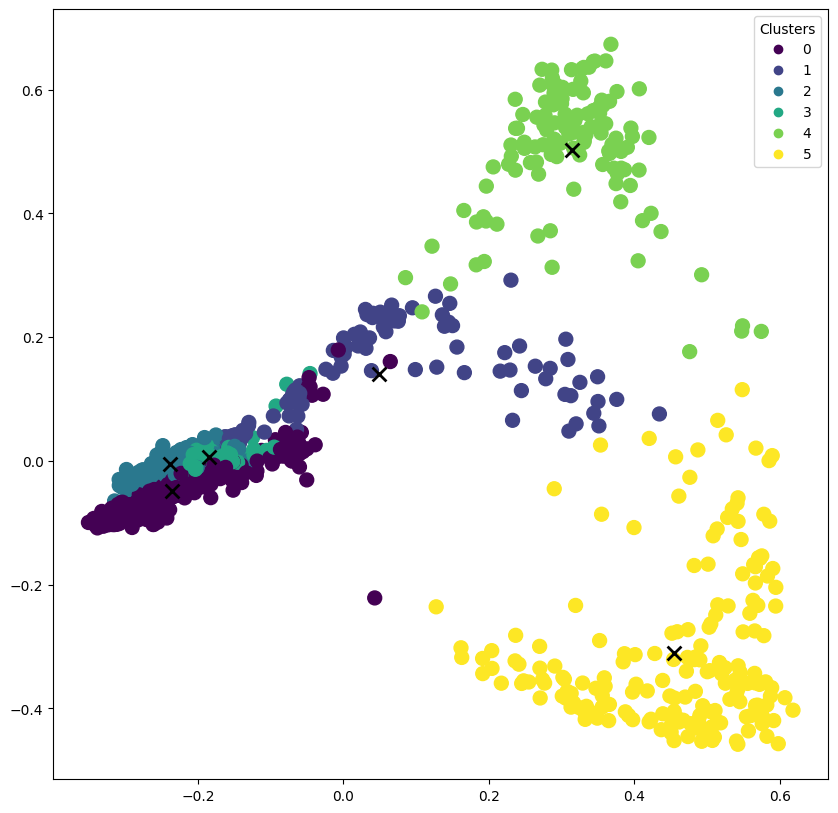

In [177]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")

# Enregistrer l'image
os.makedirs(temp_path, exist_ok=True)
plt.savefig(
    os.path.join(temp_path, f"tp3clusters_{N_CLUSTERS}.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()